In [1]:
import os
import pandas as pd
import numpy as np
from pprint import pprint

import matplotlib.pyplot as plt
%matplotlib inline
plt.style.use('ggplot')
import seaborn as sns

In [2]:
os.chdir("F:\\PROJECTS\\Data_Tales\\Steel plate faults")

In [3]:
df = pd.read_csv("train.csv")

In [4]:
df_test = pd.read_csv("test.csv")

In [5]:
df.shape

(1358, 28)

In [6]:
df_test.shape

(582, 27)

In [7]:
df.head()

,X_Minimum,X_Maximum,Y_Minimum,Y_Maximum,Pixels_Areas,X_Perimeter,Y_Perimeter,Sum_of_Luminosity,Minimum_of_Luminosity,Maximum_of_Luminosity,...,Edges_X_Index,Edges_Y_Index,Outside_Global_Index,LogOfAreas,Log_X_Index,Log_Y_Index,Orientation_Index,Luminosity_Index,SigmoidOfAreas,Faults
0,24,38,2563219,2563241,173,22,23,17100,85,111,...,0.6364,0.9565,1.0,2.2380,1.1461,1.3424,0.3636,-0.2278,0.5096,0
1,35,75,2412964,2412966,65,40,3,8355,85,165,...,1.0000,0.6667,0.0,1.8129,1.6021,0.3010,-0.9500,0.0042,0.1852,0
2,165,176,1293999,1294012,106,11,13,11973,96,128,...,1.0000,1.0000,1.0,2.0253,1.0414,1.1139,0.1539,-0.1176,0.2570,1
3,19,57,103914,103916,54,38,2,7498,101,180,...,1.0000,1.0000,0.0,1.7324,1.5798,0.3010,-0.9474,0.0848,0.1812,0
4,41,216,1555596,1555663,6562,255,125,677554,36,125,...,0.6863,0.5360,0.0,3.8170,2.2430,1.8261,-0.6171,-0.1933,1.0000,0


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1358 entries, 0 to 1357
Data columns (total 28 columns):
X_Minimum                1358 non-null int64
X_Maximum                1358 non-null int64
Y_Minimum                1358 non-null int64
Y_Maximum                1358 non-null int64
Pixels_Areas             1358 non-null int64
X_Perimeter              1358 non-null int64
Y_Perimeter              1358 non-null int64
Sum_of_Luminosity        1358 non-null int64
Minimum_of_Luminosity    1358 non-null int64
Maximum_of_Luminosity    1358 non-null int64
Length_of_Conveyer       1358 non-null int64
TypeOfSteel_A300         1358 non-null int64
TypeOfSteel_A400         1358 non-null int64
Steel_Plate_Thickness    1358 non-null int64
Edges_Index              1358 non-null float64
Empty_Index              1358 non-null float64
Square_Index             1358 non-null float64
Outside_X_Index          1358 non-null float64
Edges_X_Index            1358 non-null float64
Edges_Y_Index            135

In [9]:
df.describe()

,X_Minimum,X_Maximum,Y_Minimum,Y_Maximum,Pixels_Areas,X_Perimeter,Y_Perimeter,Sum_of_Luminosity,Minimum_of_Luminosity,Maximum_of_Luminosity,...,Edges_X_Index,Edges_Y_Index,Outside_Global_Index,LogOfAreas,Log_X_Index,Log_Y_Index,Orientation_Index,Luminosity_Index,SigmoidOfAreas,Faults
count,1358.000000,1358.00000,1.358000e+03,1.358000e+03,1358.000000,1358.000000,1358.000000,1.358000e+03,1358.000000,1358.000000,...,1358.000000,1358.000000,1358.000000,1358.000000,1358.000000,1358.000000,1358.000000,1358.000000,1358.000000,1358.000000
mean,588.991163,634.07732,1.654509e+06,1.654567e+06,1888.775405,112.301915,86.407953,2.045521e+05,84.912371,129.961708,...,0.608851,0.821383,0.589838,2.476242,1.322583,1.400372,0.096385,-0.131905,0.576124,0.208395
std,525.394695,502.01739,1.779758e+06,1.779776e+06,5640.354674,338.746956,504.547389,5.394856e+05,32.358536,18.537659,...,0.244795,0.230657,0.479913,0.783263,0.474097,0.455741,0.495383,0.151322,0.336750,0.406310
min,0.000000,4.00000,6.712000e+03,6.724000e+03,2.000000,2.000000,1.000000,2.500000e+02,0.000000,37.000000,...,0.014400,0.105000,0.000000,0.301000,0.301000,0.000000,-0.973900,-0.998900,0.119000,0.000000
25%,54.500000,192.00000,4.769258e+05,4.769358e+05,83.000000,15.000000,13.000000,9.370500e+03,64.000000,124.000000,...,0.400000,0.625000,0.000000,1.919100,1.000000,1.079200,-0.262625,-0.195675,0.245100,0.000000
50%,475.500000,507.50000,1.187171e+06,1.187248e+06,169.000000,25.000000,24.000000,1.858050e+04,90.500000,127.000000,...,0.635500,0.954050,1.000000,2.227900,1.146100,1.301000,0.103250,-0.133300,0.477900,0.000000
75%,1063.000000,1080.00000,2.195068e+06,2.195090e+06,746.500000,76.750000,76.000000,7.128525e+04,106.750000,140.000000,...,0.800000,1.000000,1.000000,2.873025,1.505100,1.724300,0.513625,-0.066525,0.999575,0.000000
max,1705.000000,1713.00000,1.298766e+07,1.298769e+07,152655.000000,10449.000000,18152.000000,1.159141e+07,203.000000,253.000000,...,1.000000,1.000000,1.000000,5.183700,3.074100,4.258700,0.991700,0.642100,1.000000,1.000000


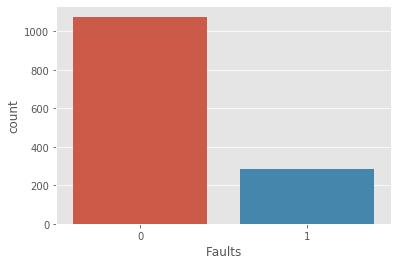

In [10]:
sns.countplot(df.Faults)
plt.show()

In [11]:
df.isna().sum()

X_Minimum                0
X_Maximum                0
Y_Minimum                0
Y_Maximum                0
Pixels_Areas             0
X_Perimeter              0
Y_Perimeter              0
Sum_of_Luminosity        0
Minimum_of_Luminosity    0
Maximum_of_Luminosity    0
Length_of_Conveyer       0
TypeOfSteel_A300         0
TypeOfSteel_A400         0
Steel_Plate_Thickness    0
Edges_Index              0
Empty_Index              0
Square_Index             0
Outside_X_Index          0
Edges_X_Index            0
Edges_Y_Index            0
Outside_Global_Index     0
LogOfAreas               0
Log_X_Index              0
Log_Y_Index              0
Orientation_Index        0
Luminosity_Index         0
SigmoidOfAreas           0
Faults                   0
dtype: int64

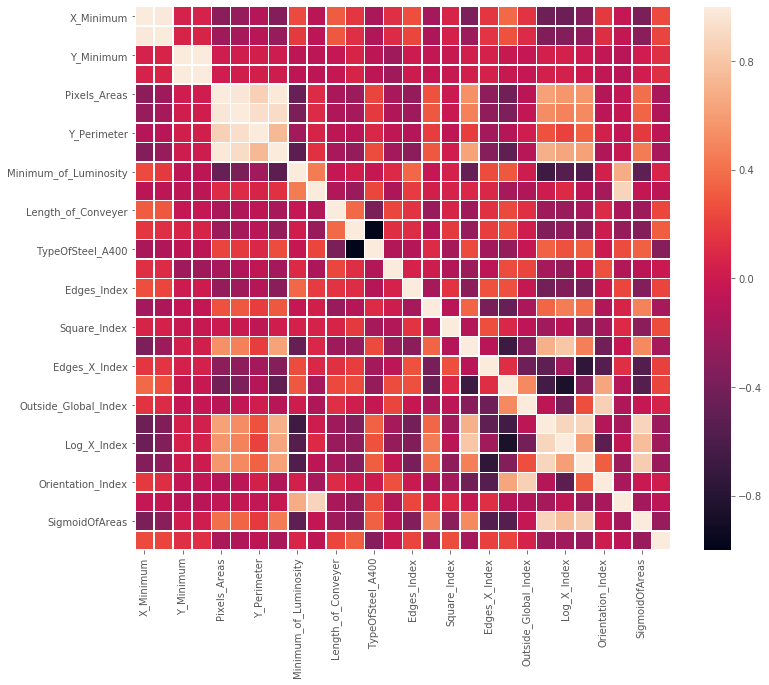

In [12]:
sns.heatmap(df.corr(), linewidths=.5)
fig = plt.gcf()
fig.set_size_inches(12,10)
plt.show()

In [13]:
corr_matrix = df.corr().abs()
#corr_matrix
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(np.bool))
to_drop = [column for column in upper.columns if any(upper[column] > 0.90)]
to_drop

['X_Maximum',
 'Y_Maximum',
 'X_Perimeter',
 'Y_Perimeter',
 'Sum_of_Luminosity',
 'TypeOfSteel_A400']

In [14]:
#Dropping highly correlated features
df.drop(to_drop, axis = 1, inplace = True)

### Outlier Analysis

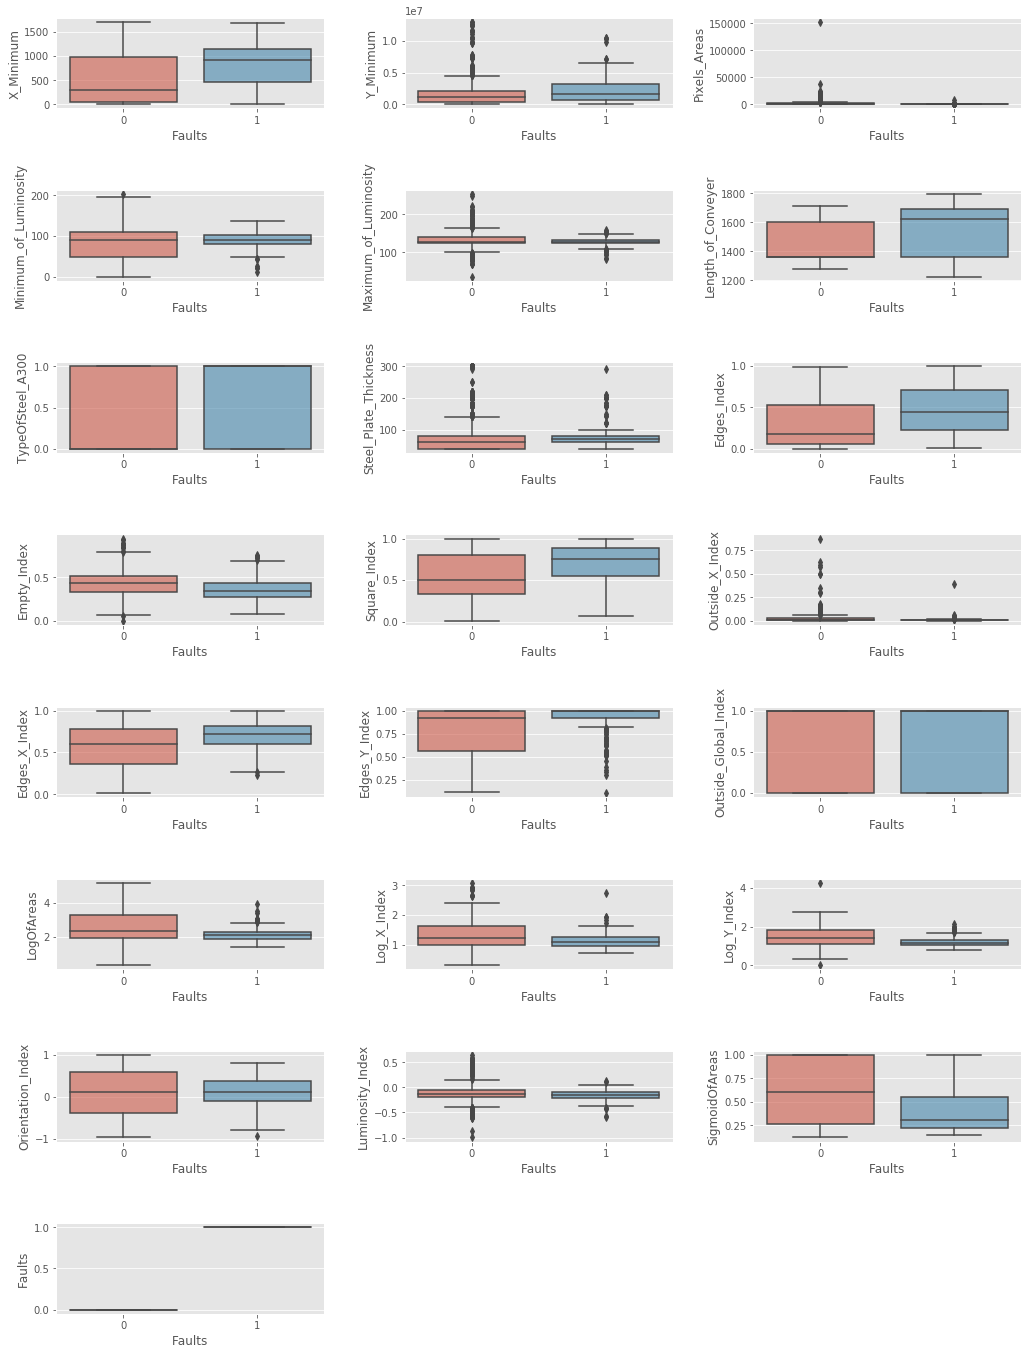

In [15]:
plt.figure(figsize=(8, 20))
for i, col in enumerate(df.columns):
    plt.subplot(8, 3, i+1)
    ax = sns.boxplot(x="Faults", y=col, data=df)
    #Add transperancy to plots
    for patch in ax.artists:
        r, g, b, a = patch.get_facecolor()
        patch.set_facecolor((r, g, b, 0.6))
#Adjust plots
plt.subplots_adjust(left=0.125, bottom=0.1, right=1.8, top=1.0, wspace=0.3, hspace=0.9)
plt.show()

In [16]:
outlier_columns = ['Y_Minimum','Pixels_Areas', 'Minimum_of_Luminosity','Maximum_of_Luminosity','Steel_Plate_Thickness','Empty_Index',
                   'Outside_X_Index', 'LogOfAreas','Edges_Y_Index']

In [17]:
df_outliers = df[outlier_columns]
df_outliers.shape

(1358, 9)

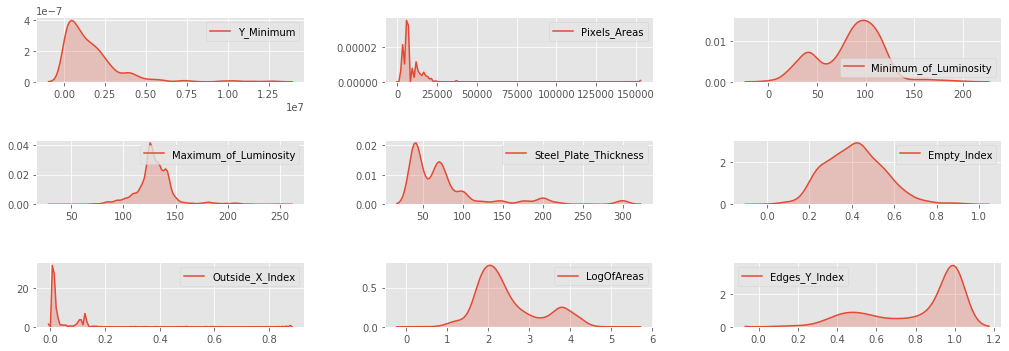

In [18]:
plt.figure(figsize=(8, 20))
#Visualizing distributions of columns with outliers
for i, col in enumerate(df_outliers.columns):
    plt.subplot(4, 3, i+1)
    sns.kdeplot(df_outliers[col], shade = True)
    #Add transperancy to plots
    for patch in ax.artists:
        r, g, b, a = patch.get_facecolor()
        patch.set_facecolor((r, g, b, 0.6))

#Adjust plots
plt.subplots_adjust(left=0.125, bottom=0.1, right=1.8, top=0.4, wspace=0.3, hspace=0.9)
plt.show()

In [19]:
df.columns

Index(['X_Minimum', 'Y_Minimum', 'Pixels_Areas', 'Minimum_of_Luminosity',
       'Maximum_of_Luminosity', 'Length_of_Conveyer', 'TypeOfSteel_A300',
       'Steel_Plate_Thickness', 'Edges_Index', 'Empty_Index', 'Square_Index',
       'Outside_X_Index', 'Edges_X_Index', 'Edges_Y_Index',
       'Outside_Global_Index', 'LogOfAreas', 'Log_X_Index', 'Log_Y_Index',
       'Orientation_Index', 'Luminosity_Index', 'SigmoidOfAreas', 'Faults'],
      dtype='object')

Checking to see the distribution of outlier columns. Idea is to check, if occurence of outliers means something. Or if outliers helps to classify steel palte faults.

In [20]:
#getting the index of each outlier per column and plotting distribution
def get_outlier_indices(col):
    col_values = df[col].values
    col_mean, col_std = np.mean(col_values), np.std(col_values)
    cut_off = col_std * 3
    lower,upper = col_mean - cut_off, col_mean + cut_off
    col_lower = col_values < lower
    col_upper = col_values > upper
    col_is_outlier = np.logical_xor(col_lower, col_upper)
    col_outlier_index = np.argwhere(col_is_outlier == True).flatten()
    return col_outlier_index

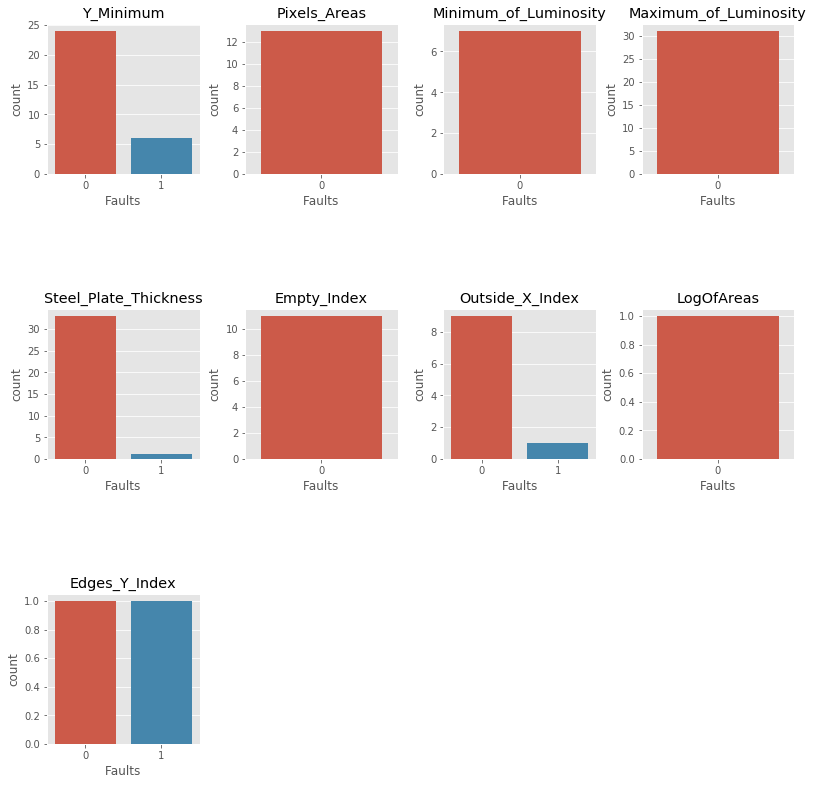

In [21]:
plt.figure(figsize=(5, 50))

for i, col in enumerate(df_outliers.columns):
    indices = get_outlier_indices(col)
    plt.subplot(3,4, i+1)
    sns.countplot(df.loc[indices,:]["Faults"])
    plt.title(col)
    #Adjust plots
plt.subplots_adjust(left=0.125, bottom=0.1, right=2.2, top=0.3, wspace=0.3, hspace=0.9)
plt.show()

For most of the columns like: 'Pixels_Areas', 'Mininimum of Luminosity', 'Log_X_Index', most of the outlier points fall under only one class. So, there might be a reason behind this. So, instead of removing outliers for those columns we can keep them.

Log transforming right skewed columns.

In [22]:
right_skewed_cols = ['Y_Minimum','Pixels_Areas','Steel_Plate_Thickness', 'Outside_X_Index']
df[right_skewed_cols] = np.log1p(df[right_skewed_cols])

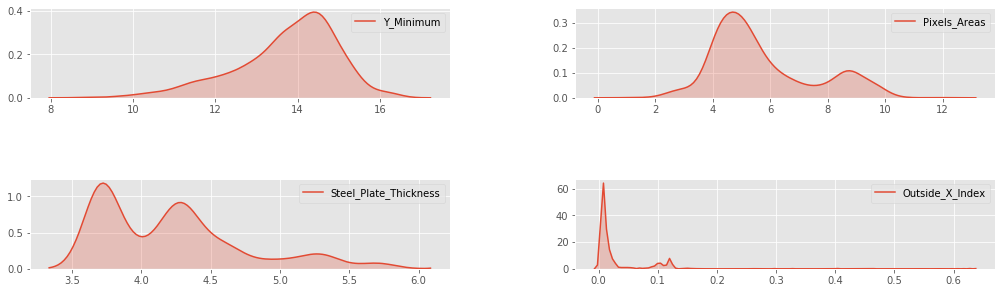

In [23]:
plt.figure(figsize=(8, 20))
for i, col in enumerate(right_skewed_cols):
    plt.subplot(3,2, i+1)
    sns.kdeplot(df[col], shade = True)
    #Add transperancy to plots
    for patch in ax.artists:
        r, g, b, a = patch.get_facecolor()
        patch.set_facecolor((r, g, b, 0.6))

#Adjust plots
plt.subplots_adjust(left=0.125, bottom=0.1, right=1.8, top=0.4, wspace=0.3, hspace=0.9)
plt.show()

In [24]:
target = df.Faults.values

In [25]:
df.drop('Faults', axis = 1, inplace = True)

## Model Building

In [26]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split,KFold
def pre_process_and_split(data):
    scaler = StandardScaler()
    scaler = scaler.fit(data)
    data_scaled = scaler.transform(data)
    X_train, X_val, y_train, y_val = train_test_split(data_scaled, target, test_size = 0.25, random_state = 45)
    return (X_train, X_val, y_train, y_val,scaler)

In [27]:
df.shape

(1358, 21)

In [28]:
X_train, X_val, y_train, y_val, scaler = pre_process_and_split(df)

### various models

In [29]:
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.model_selection import KFold,cross_val_score

In [30]:
seed = 7
scoring = 'accuracy'

In [31]:
models = []
models.append(('LR', LogisticRegression()))
models.append(('KNN', KNeighborsClassifier()))
models.append(('CART', DecisionTreeClassifier()))
models.append(('NB', GaussianNB()))
models.append(('SVM', SVC(gamma='auto')))

results = []
names = []

for name, model in models:
    kfold = KFold(n_splits = 5, random_state = seed)
    cv_results = cross_val_score(model, X_train, y_train, cv = kfold, scoring = scoring)
    results.append(cv_results)
    names.append(name)
    msg = f"{name}: Mean -> {cv_results.mean()}, std -> {cv_results.std()}"
    print(msg)

C:\Users\Chinna\Anaconda3\lib\site-packages\sklearn\linear_model\logistic.py:432: FutureWarning: Default solver will be changed to 'lbfgs' in 0.22. Specify a solver to silence this warning.
  FutureWarning)
C:\Users\Chinna\Anaconda3\lib\site-packages\sklearn\linear_model\logistic.py:432: FutureWarning: Default solver will be changed to 'lbfgs' in 0.22. Specify a solver to silence this warning.
  FutureWarning)
C:\Users\Chinna\Anaconda3\lib\site-packages\sklearn\linear_model\logistic.py:432: FutureWarning: Default solver will be changed to 'lbfgs' in 0.22. Specify a solver to silence this warning.
  FutureWarning)
C:\Users\Chinna\Anaconda3\lib\site-packages\sklearn\linear_model\logistic.py:432: FutureWarning: Default solver will be changed to 'lbfgs' in 0.22. Specify a solver to silence this warning.
  FutureWarning)
C:\Users\Chinna\Anaconda3\lib\site-packages\sklearn\linear_model\logistic.py:432: FutureWarning: Default solver will be changed to 'lbfgs' in 0.22. Specify a solver to sile

LR: Mean -> 0.8329759490002898, std -> 0.025255412071718063
KNN: Mean -> 0.8575533661740558, std -> 0.016506781070560538
CART: Mean -> 0.8192407997681832, std -> 0.013874647991246488
NB: Mean -> 0.6709697672172318, std -> 0.02009484853860124
SVM: Mean -> 0.85755819569207, std -> 0.021983308191325126


Picked SCM as it has high accuracy. Tuning it to get better results and checking on val set.

In [32]:
svc = SVC()
params = {"C":[0.01, 0.1, 1, 10],
         "gamma":[0.001, 0.01, 0.1, 1],
         "kernel":["rbf","linear"]}

In [33]:
from sklearn.model_selection import GridSearchCV
grid = GridSearchCV(estimator = svc, param_grid = params)
grid.fit(X_train, y_train)

C:\Users\Chinna\Anaconda3\lib\site-packages\sklearn\model_selection\_split.py:1978: FutureWarning: The default value of cv will change from 3 to 5 in version 0.22. Specify it explicitly to silence this warning.
  warnings.warn(CV_WARNING, FutureWarning)


GridSearchCV(cv='warn', error_score='raise-deprecating',
             estimator=SVC(C=1.0, cache_size=200, class_weight=None, coef0=0.0,
                           decision_function_shape='ovr', degree=3,
                           gamma='auto_deprecated', kernel='rbf', max_iter=-1,
                           probability=False, random_state=None, shrinking=True,
                           tol=0.001, verbose=False),
             iid='warn', n_jobs=None,
             param_grid={'C': [0.01, 0.1, 1, 10],
                         'gamma': [0.001, 0.01, 0.1, 1],
                         'kernel': ['rbf', 'linear']},
             pre_dispatch='2*n_jobs', refit=True, return_train_score=False,
             scoring=None, verbose=0)

In [34]:
grid.best_params_

{'C': 10, 'gamma': 0.1, 'kernel': 'rbf'}

In [35]:
svc = SVC(C = 10, gamma = 0.1, kernel = 'rbf', random_state=43)
svc.fit(X_train, y_train)
preds = svc.predict(X_val)
acc = accuracy_score(y_val,preds)
print(acc*100)

80.0


In [36]:
confusion_matrix(y_val, preds)

array([[239,  30],
       [ 38,  33]], dtype=int64)

#### RANDOM FORESTS

In [37]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV

In [38]:
# Number of trees in random forest
n_estimators = [int(x) for x in np.linspace(start = 10, stop = 100, num = 10)]

# Number of features to consider at every split
max_features = ['auto', 'sqrt']

# Maximum number of levels in tree
max_depth = [int(x) for x in np.linspace(10, 110, num = 11)]
max_depth.append(None)

# Minimum number of samples required to split a node
min_samples_split = [2, 5, 10]

# Minimum number of samples required at each leaf node
min_samples_leaf = [1, 2, 4]

# Method of selecting samples for training each tree
bootstrap = [True, False]

In [39]:
# Create the random grid
random_grid = {'n_estimators': n_estimators,
               'max_features': max_features,
               'max_depth': max_depth,
               'min_samples_split': min_samples_split,
               'min_samples_leaf': min_samples_leaf,
               'bootstrap': bootstrap}

pprint(random_grid)

{'bootstrap': [True, False],
 'max_depth': [10, 20, 30, 40, 50, 60, 70, 80, 90, 100, 110, None],
 'max_features': ['auto', 'sqrt'],
 'min_samples_leaf': [1, 2, 4],
 'min_samples_split': [2, 5, 10],
 'n_estimators': [10, 20, 30, 40, 50, 60, 70, 80, 90, 100]}


In [ ]:
rf = RandomForestClassifier()
rf_random = RandomizedSearchCV(estimator = rf, param_distributions = random_grid, n_iter = 100, cv = 3, 
                               verbose=2, random_state=42, n_jobs = -1)

rf_random.fit(X_train, y_train)

Fitting 3 folds for each of 100 candidates, totalling 300 fits


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 4 concurrent workers.


In [ ]:
rf_random.best_params_

In [ ]:
rf = RandomForestClassifier(n_estimators = 50, max_features = 'sqrt', max_depth = 80,
                            min_samples_leaf = 1,min_samples_split = 10, random_state=43)


rf.fit(X_train, y_train)

In [ ]:
preds = rf.predict(X_val)
acc = accuracy_score(y_val,preds)
print(acc)

In [ ]:
confusion_matrix(y_val, preds)